# 4. Hype cycles without a media bump

Notebook 2 produced the hype cycle with a media campaign that rises and fades. Can the cycle appear with
**constant** media frequency and message, from agents who start with a low common prior ($v_0=0.3$)?
Here the overshoot would have to come from the agents' own dynamics: expectations rise towards the message
($wP=1.5$), adopters then report the realised value ($r<r_\infty=0.8$) and pull expectations down, and
investment later lifts $r$.

Signals: $\mu=1$, $w=1.5$, $P=1$, $I_{\rm exo}=0.1\,t$. DSMC with $N=10^4$, one seed, interaction
rates $\mu_c$ from 125 to 8000 per agent per unit time (the same symbol as in the paper).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kinetic_hype import hype_features
from kinetic_hype.plotting import use_style, QUANTITY, INK, INK_2

use_style()
RES = Path("..") / "results"
traj = pd.read_csv(RES / "trajectories_fixed.csv")
ref = pd.read_csv(RES / "meanfield_fixed.csv")
rates = sorted(traj.mu_c.unique())
print("interaction rates mu_c:", [int(m) for m in rates])

interaction rates mu_c: [125, 250, 500, 1000, 2000, 4000, 8000]


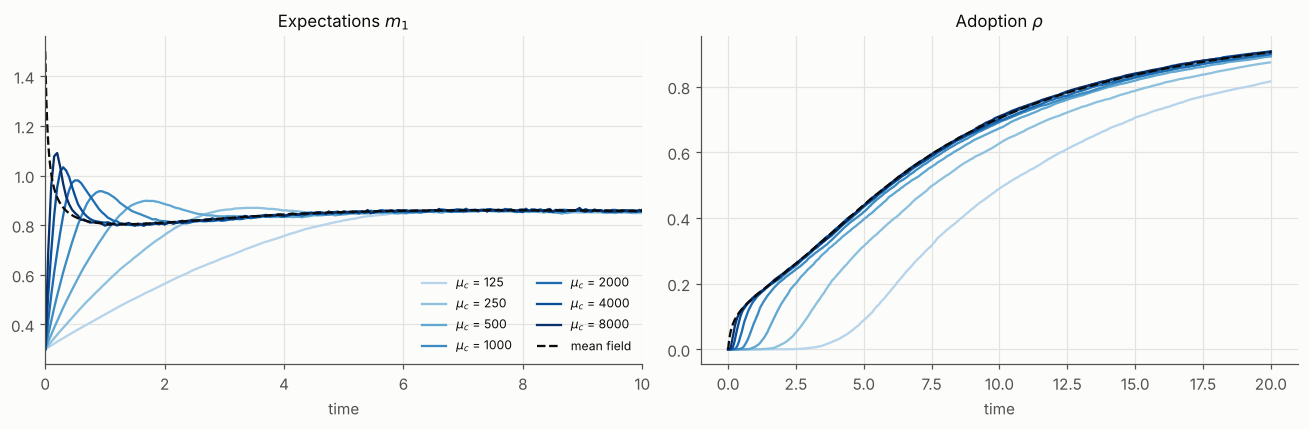

In [2]:
shades = plt.cm.Blues(np.linspace(0.3, 1.0, len(rates)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, c in zip(rates, shades):
    d = traj[traj.mu_c == m]
    axes[0].plot(d.t, d.m1, color=c, lw=1.5, label=rf"$\mu_c$ = {m:g}")
    axes[1].plot(d.t, d.rho, color=c, lw=1.5)
axes[0].plot(ref.t, ref.m1, color=INK, ls="--", lw=1.5, label="mean field")
axes[1].plot(ref.t, ref.rho, color=INK, ls="--", lw=1.5, label="mean field")
axes[0].set_title(r"Expectations $m_1$"); axes[1].set_title(r"Adoption $\rho$")
axes[0].set_xlim(0, 10)
for ax in axes: ax.set_xlabel("time")
axes[0].legend(loc="lower right", fontsize=8, ncol=2); fig.tight_layout()

In [3]:
feat = pd.read_csv(RES / "fixed_signals_features.csv")
mfh = hype_features(ref)
feat = pd.concat([feat, pd.DataFrame([{"mu_c": np.inf, "t_peak": mfh.t_peak, "peak": mfh.peak,
                  "t_trough": mfh.t_trough, "trough": mfh.trough, "final": mfh.final,
                  "drop": mfh.drop, "recovery": mfh.recovery,
                  "hype_cycle": mfh.is_hype_cycle(t_min=0.1)}])], ignore_index=True)
feat["rho_t20"] = [traj[traj.mu_c == m].rho.iloc[-1] for m in rates] + [ref.rho.iloc[-1]]
feat.round(3)

,mu_c,t_peak,peak,t_trough,trough,final,drop,recovery,hype_cycle,rho_t20
0,125.0,7.104,0.860,19.920,0.835,0.835,0.025,0.000,False,0.816
1,250.0,3.456,0.870,19.968,0.837,0.837,0.033,0.000,False,0.874
2,500.0,1.750,0.897,3.550,0.833,0.845,0.064,0.013,True,0.892
3,1000.0,0.950,0.933,2.200,0.813,0.849,0.120,0.036,True,0.898
4,2000.0,0.550,0.971,1.600,0.800,0.849,0.170,0.049,True,0.900
5,4000.0,0.350,1.003,1.400,0.802,0.850,0.202,0.048,True,0.908
6,8000.0,0.200,1.026,1.550,0.801,0.852,0.224,0.051,True,0.906
7,inf,0.000,1.500,1.300,0.804,0.848,0.696,0.044,False,0.905


The last row ($\mu_c=\infty$) is the mean field. Peak and trough are taken on a 5-point moving average of the
DSMC series; a hype cycle requires an interior peak ($t>0.1$), a drop of at least 0.02 and a recovery of at
least 0.01.

**What the table shows.**

* **Slow relaxation ($\mu_c\le250$): no cycle.** Expectations creep up and peak late ($t\approx3.5$–7); by then
  users' reports and investment have pulled their equilibrium down, so they settle on the plateau after a
  dip of about 0.03 with no recovery.
* **$\mu_c\ge500$: a genuine cycle.** Expectations rise, peak, fall by 0.06–0.22 and recover by 0.01–0.05. The
  agents' own dynamics produce it without any time-varying media. As $\mu_c$ grows the peak comes earlier
  ($t=1.75\to0.20$) and higher ($0.90\to1.03$), while the trough stays near 0.80.
* **Mean field ($\mu_c=\infty$): no rising phase.** Expectations sit at the media equilibrium $wP=1.5$ at $t=0$,
  then fall and recover. The DSMC peaks approach this limit as the rise is compressed towards $t=0$.

So under constant signals the *rising* phase of the cycle exists only because expectations take finite
time to form. The fall and recovery survive in the mean-field limit; the full rise–peak–fall–recovery
shape does not. This supports the paper's claim that, with constant media, the cycle needs the agent
simulation without time-scale separation. It adds a lower bound: too slow a relaxation ($\mu_c\le250$ here)
gives no cycle either. The threshold between $\mu_c=250$ and $\mu_c=500$ is specific to these parameters (one seed,
one grid; not mapped further).

## Does the cycle need heterogeneity?

The same constant-media runs with and without self-reasoning noise ($\gamma=0$ against $\gamma=0.8$), at
$\mu_c=1000$ and $\mu_c=4000$ (`python scripts/run_experiments.py --only noise`).

In [4]:
pd.read_csv(RES / "fixed_signals_noise.csv").round(3)

,gam,mu_c,t_peak,peak,trough,final,drop,recovery,hype_cycle,rho_T
0,0.0,1000,0.95,1.007,0.893,0.978,0.114,0.086,True,0.195
1,0.0,4000,0.30,1.006,0.886,0.978,0.120,0.092,True,0.196
2,0.8,1000,0.95,0.933,0.813,0.849,0.120,0.036,True,0.898
3,0.8,4000,0.35,1.003,0.802,0.850,0.202,0.048,True,0.908


Without noise, expectations still rise, fall by 0.11–0.12 and recover at both rates, but adoption stalls at
about 20%: after the peak $m_1$ settles just below the price (0.98) and virtually no non-user is above it. With
noise adoption reaches about 90% by $t=20$. Heterogeneity is not needed for the cycle of expectations, but it
is needed for diffusion to accompany it.